# Shopping Behavior Analytics: Statistical Testing & Segmentation

**Notebook 2 of 2** | Input: `data/processed/shopping_clean.csv` (from Notebook 1)

## Objective
1. Test whether the differences seen in Notebook 1 are statistically real.
2. Segment customers with K-Means to find groups worth targeting differently.

## Outline
1. Load data and check correlations
2. Check the data structure (gender, subscription, discounts)
3. Hypothesis tests
4. K-Means segmentation
5. Segment profiles and recommendations

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

DATA_PATH = Path(r"D:\Customer_Behavior\data\processed\shopping_clean.csv")
df = pd.read_csv(DATA_PATH)
print(df.shape)

(3900, 23)


## 1. Correlations
Check whether any numeric variables move together: age, purchase amount, rating, and previous purchases.

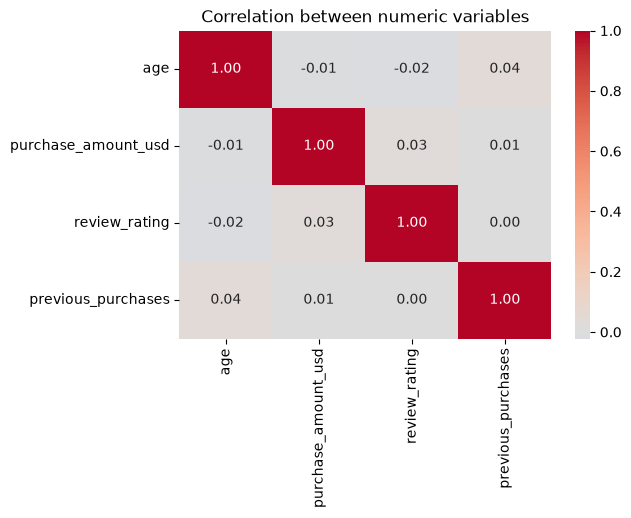

In [17]:
num_cols = ["age", "purchase_amount_usd", "review_rating", "previous_purchases"]
plt.figure(figsize=(6, 4))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between numeric variables")
plt.show()

**Finding:** Every pairwise correlation is below 0.05, which is effectively zero. Age, spend, rating, and loyalty are independent of each other.

**Implication:** No simple linear driver of spend exists. Any segments will come from combinations of variables, not one dominant factor.

## 2. Data Structure Check
Before testing group differences, check how gender, subscription, and discounts relate to each other, because overlap between groups can distort comparisons.

In [18]:
print(pd.crosstab(df["gender"], df["subscription_status"]), "\n")
print(pd.crosstab(df["gender"], df["discount_applied"]), "\n")
print(pd.crosstab(df["subscription_status"], df["discount_applied"]), "\n")
print("Discount == Promo in all rows:", (df["discount_applied"] == df["promo_code_used"]).all())

subscription_status    No   Yes
gender                         
Female               1248     0
Male                 1599  1053 

discount_applied    No   Yes
gender                      
Female            1248     0
Male               975  1677 

discount_applied       No   Yes
subscription_status            
No                   2223   624
Yes                     0  1053 

Discount == Promo in all rows: True


**Findings**
- **All 1,053 subscribers are male**, and **all 1,677 discount/promo users are male**. No female customer has a subscription or a discount.
- Every subscriber also used a discount (1,053 of 1,053), while 624 non-subscribers used one too.
- `Discount Applied` and `Promo Code Used` are identical in every row.

**Implication:** Gender, subscription, and discount are tangled together, so comparing "discount vs. no discount" across everyone also compares men vs. women. A fair test of discounts or subscriptions has to be run **within men only**. This pattern suggests a synthetic dataset or a data-collection rule, and I flag it as a limitation.

## 3. Hypothesis Tests
For each comparison I report the mean in each group, Cohen's d (effect size), and p-values from a Welch t-test and Mann-Whitney U (for two groups) or ANOVA and Kruskal-Wallis (for 3+ groups).

Because I run many tests, some will look significant by chance, so I also apply a **Bonferroni correction**, which divides the 0.05 threshold by the number of tests.

In [19]:
def two_group_test(data, group_col, yes, no, value_col):
    a = data.loc[data[group_col] == yes, value_col]
    b = data.loc[data[group_col] == no, value_col]
    t_p = stats.ttest_ind(a, b, equal_var=False).pvalue
    u_p = stats.mannwhitneyu(a, b).pvalue
    pooled_sd = np.sqrt((a.var() + b.var()) / 2)
    return {"test": f"{group_col}: {yes} vs {no}", "metric": value_col,
            "mean_a": round(a.mean(), 2), "mean_b": round(b.mean(), 2),
            "cohens_d": round((a.mean() - b.mean()) / pooled_sd, 3),
            "p_value": round(t_p, 4), "p_mannwhitney": round(u_p, 4)}

def multi_group_test(data, group_col, value_col):
    groups = [g[value_col].values for _, g in data.groupby(group_col)]
    return {"test": f"{group_col} (ANOVA)", "metric": value_col,
            "p_value": round(stats.f_oneway(*groups).pvalue, 4),
            "p_kruskal": round(stats.kruskal(*groups).pvalue, 4)}

metrics = ["purchase_amount_usd", "review_rating", "previous_purchases"]
rows = []
for col, yes, no in [("discount_applied", "Yes", "No"),
                     ("subscription_status", "Yes", "No"),
                     ("gender", "Female", "Male")]:
    for m in metrics:
        rows.append(two_group_test(df, col, yes, no, m))
for col in ["season", "category", "shipping_type", "payment_method", "frequency_of_purchases"]:
    for m in ["purchase_amount_usd", "review_rating"]:
        rows.append(multi_group_test(df, col, m))

results = pd.DataFrame(rows)
alpha = 0.05
bonf = alpha / len(results)
results["sig_at_0.05"] = results["p_value"] < alpha
results["sig_after_bonferroni"] = results["p_value"] < bonf
print(f"{len(results)} tests | Bonferroni threshold = {bonf:.4f}")
results.sort_values("p_value")

19 tests | Bonferroni threshold = 0.0026


,test,metric,mean_a,mean_b,cohens_d,p_value,p_mannwhitney,p_kruskal,sig_at_0.05,sig_after_bonferroni
9,season (ANOVA),purchase_amount_usd,NaN,NaN,NaN,0.0106,NaN,0.0098,True,False
8,gender: Female vs Male,previous_purchases,24.60,25.71,-0.077,0.0259,0.0245,NaN,True,False
14,shipping_type (ANOVA),review_rating,NaN,NaN,NaN,0.0384,NaN,0.0387,True,False
5,subscription_status: Yes vs No,previous_purchases,26.08,25.08,0.070,0.0509,0.0525,NaN,False,False
2,discount_applied: Yes vs No,previous_purchases,25.74,25.06,0.048,0.1416,0.1421,NaN,False,False
12,category (ANOVA),review_rating,NaN,NaN,NaN,0.1566,NaN,0.1537,False,False
10,season (ANOVA),review_rating,NaN,NaN,NaN,0.1657,NaN,0.1679,False,False
11,category (ANOVA),purchase_amount_usd,NaN,NaN,NaN,0.2252,NaN,0.2203,False,False
0,discount_applied: Yes vs No,purchase_amount_usd,59.28,60.13,-0.036,0.2661,0.2607,NaN,False,False
13,shipping_type (ANOVA),purchase_amount_usd,NaN,NaN,NaN,0.3451,NaN,0.3478,False,False


**Findings** (19 tests, Bonferroni threshold = 0.0026)
- Three results pass the usual 0.05 cutoff:
  - **Season vs. spend** (p = 0.011): Fall averages $61.56 and Summer $58.41. The effect is tiny (eta-squared of about 0.003, so season explains 0.3% of spend variation).
  - **Gender vs. previous purchases** (p = 0.026): women 24.6, men 25.7 (d = -0.08).
  - **Shipping type vs. rating** (p = 0.038).
- **None survive the Bonferroni correction.** With 19 tests, roughly one false positive is expected at 0.05, so these are most likely noise.
- Discount vs. spend: p = 0.27 (d = -0.04). Subscription vs. spend: p = 0.66 (d = -0.02). Both are effectively zero.
- Subscription vs. previous purchases is borderline (p = 0.051, d = 0.07), still a very small effect.

**Takeaway:** Nothing here supports a business action on its own. Spend and ratings are essentially uniform across the groups tested.

### Fair comparison: men only
Because only men have discounts and subscriptions, rerun those two tests inside the male group to remove the gender confound.

In [20]:
males = df[df["gender"] == "Male"]
pd.DataFrame([
    two_group_test(males, "discount_applied", "Yes", "No", "purchase_amount_usd"),
    two_group_test(males, "subscription_status", "Yes", "No", "purchase_amount_usd"),
])

,test,metric,mean_a,mean_b,cohens_d,p_value,p_mannwhitney
0,discount_applied: Yes vs No,purchase_amount_usd,59.28,59.98,-0.029,0.4686,0.4618
1,subscription_status: Yes vs No,purchase_amount_usd,59.49,59.57,-0.003,0.9378,0.9520


**Findings (men only, n = 2,652)**
- Discount users spend **$59.28 vs. $59.98** for non-users (p = 0.47, d = -0.03).
- Subscribers spend **$59.49 vs. $59.57** for non-subscribers (p = 0.94, d = -0.003).

**Takeaway:** Even with the gender overlap removed, discounts and subscriptions show **no increase in spend per order**. If discounts cost margin, this data gives no evidence they pay for themselves. Repeat purchases and retention can't be tested here, since the data has one purchase per customer.

## 4. Customer Segmentation (K-Means)

**Features:** age, purchase amount, previous purchases, review rating. These are scaled so no variable dominates.

**Why not subscription and discount flags?** They are tied to gender (see Section 2), so including them would split customers by that structure instead of by behavior. I profile segments on those fields afterwards instead.

In [21]:
features = ["age", "purchase_amount_usd", "previous_purchases", "review_rating"]
X = StandardScaler().fit_transform(df[features])
X.shape

(3900, 4)

Features are standardized to mean 0 and standard deviation 1, so a $1 change in spend and a 1-year change in age are compared on equal terms.

### Choosing the number of clusters
Use the elbow method (inertia) and the silhouette score (cluster separation, where higher is better) for k = 2 to 8.

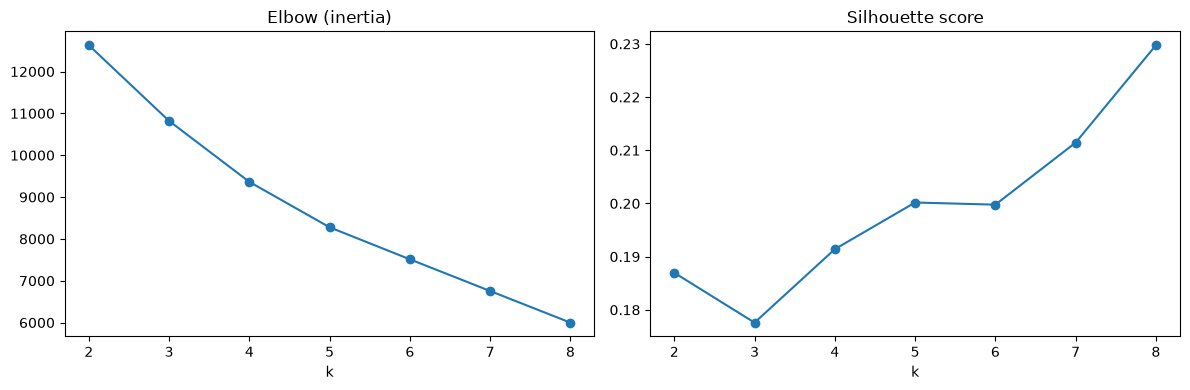

{2: 0.187, 3: 0.178, 4: 0.191, 5: 0.2, 6: 0.2, 7: 0.211, 8: 0.23}


In [22]:
ks = range(2, 9)
inertias, sils = [], []
for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(X, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ks, inertias, marker="o"); ax[0].set_title("Elbow (inertia)"); ax[0].set_xlabel("k")
ax[1].plot(ks, sils, marker="o"); ax[1].set_title("Silhouette score"); ax[1].set_xlabel("k")
plt.tight_layout(); plt.show()
print({k: round(float(s), 3) for k, s in zip(ks, sils)})

**Findings**
- Silhouette scores are low everywhere (0.18 to 0.23, where 0.5+ means clear separation), and the elbow curve has no sharp bend.
- That means the customers form **one continuous cloud**, not naturally separate groups.

**Decision:** I use **k = 4**. There is no statistically "correct" k here, so I chose it because it gives four interpretable segments of near-equal size. The segments are a practical way to divide customers, not discovered natural clusters.

### Fit K-Means (k = 4) and profile each cluster

In [23]:
K = 4
km = KMeans(n_clusters=K, random_state=42, n_init=10).fit(X)
df["cluster"] = km.labels_

profile = df.groupby("cluster").agg(
    customers=("customer_id", "count"),
    avg_age=("age", "mean"),
    avg_spend=("purchase_amount_usd", "mean"),
    avg_prev_purchases=("previous_purchases", "mean"),
    avg_rating=("review_rating", "mean"),
    pct_subscribed=("subscription_status_flag", "mean"),
    pct_discount=("discount_applied_flag", "mean"),
    pct_male=("gender", lambda s: (s == "Male").mean()),
).round(2)
profile["revenue_share_pct"] = (
    df.groupby("cluster")["purchase_amount_usd"].sum() / df["purchase_amount_usd"].sum() * 100
).round(1)
profile

,customers,avg_age,avg_spend,avg_prev_purchases,avg_rating,pct_subscribed,pct_discount,pct_male,revenue_share_pct
cluster,,,,,,,,,
0,966,56.22,82.08,26.76,3.96,0.27,0.42,0.67,34.0
1,969,31.33,54.86,24.98,4.43,0.26,0.42,0.69,22.8
2,986,32.59,64.76,22.44,3.09,0.27,0.43,0.66,27.4
3,979,56.26,37.57,27.26,3.54,0.28,0.45,0.70,15.8


**Findings**
- Segments split on **age** (about 31-33 vs. 56) and then on **spend and rating**.
- Each has roughly 970-990 customers.
- Subscription rate (26-28%), discount rate (42-45%), and male share (66-70%) are nearly identical across segments, so those fields don't distinguish them.

In [24]:
overall = df[["age", "purchase_amount_usd", "review_rating"]].mean()

def name_segment(r):
    older = r["avg_age"] >= overall["age"]
    high_spend = r["avg_spend"] >= overall["purchase_amount_usd"]
    if older and high_spend:
        return "Older High Spenders"
    if older:
        return "Older Low Spenders"
    if r["avg_rating"] < overall["review_rating"]:
        return "Young At-Risk (Low Rating)"
    return "Young Satisfied Buyers"

names = profile.apply(name_segment, axis=1)
assert names.is_unique, "Names collided, so name segments manually from the profile table"
df["segment"] = df["cluster"].map(names)
profile["segment"] = names
profile.set_index("segment")

,customers,avg_age,avg_spend,avg_prev_purchases,avg_rating,pct_subscribed,pct_discount,pct_male,revenue_share_pct
segment,,,,,,,,,
Older High Spenders,966,56.22,82.08,26.76,3.96,0.27,0.42,0.67,34.0
Young Satisfied Buyers,969,31.33,54.86,24.98,4.43,0.26,0.42,0.69,22.8
Young At-Risk (Low Rating),986,32.59,64.76,22.44,3.09,0.27,0.43,0.66,27.4
Older Low Spenders,979,56.26,37.57,27.26,3.54,0.28,0.45,0.70,15.8


## Segment Profiles

| Segment | Customers | Avg age | Avg spend | Avg rating | Revenue share |
|---|---|---|---|---|---|
| **Older High Spenders** | 966 | 56 | $82.08 | 3.96 | **34.0%** |
| **Young At-Risk (Low Rating)** | 986 | 33 | $64.76 | **3.09** | 27.4% |
| **Young Satisfied Buyers** | 969 | 31 | $54.86 | **4.43** | 22.8% |
| **Older Low Spenders** | 979 | 56 | **$37.57** | 3.54 | 15.8% |

**Reading the segments**
- **Older High Spenders** are the most valuable group: 25% of customers but 34% of revenue.
- **Young At-Risk** spend above average but are the unhappiest (rating 3.09), a retention risk worth investigating.
- **Young Satisfied Buyers** are the happiest but spend below average, so they are an upsell opportunity.
- **Older Low Spenders** spend the least ($37.57, less than half of the top segment), so they are a candidate for bundles or cross-sell.

### Visualize the segments
A 2D PCA projection shows how the segments sit relative to each other, next to revenue by segment.

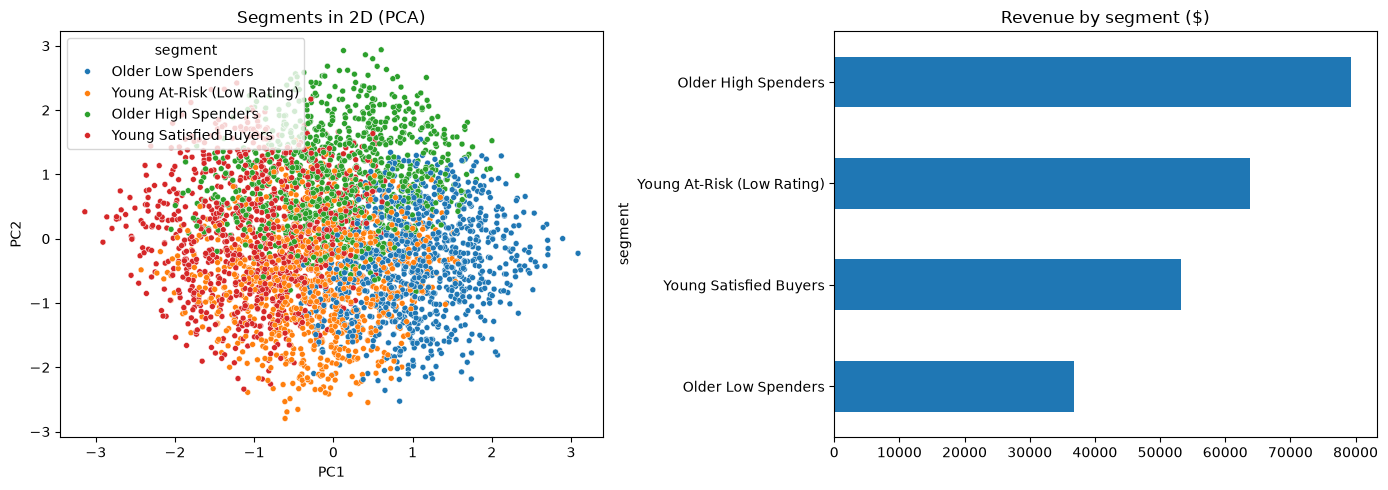

In [25]:
coords = PCA(n_components=2, random_state=42).fit_transform(X)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=df["segment"], s=18, ax=ax[0])
ax[0].set_title("Segments in 2D (PCA)"); ax[0].set_xlabel("PC1"); ax[0].set_ylabel("PC2")

rev = df.groupby("segment")["purchase_amount_usd"].sum().sort_values()
rev.plot.barh(ax=ax[1], title="Revenue by segment ($)")
plt.tight_layout(); plt.show()

The scatter plot shows the segments as adjacent regions of one continuous cloud with no gaps between them, consistent with the low silhouette scores. The revenue chart confirms that Older High Spenders contribute the most.

### Can the segments be targeted?
A segment is only actionable if you can reach it. Check whether segments differ by category, season, gender, or subscription.

In [26]:
for col in ["category", "season", "gender", "subscription_status"]:
    print(pd.crosstab(df["segment"], df[col], normalize="index").round(2), "\n")

category                    Accessories  Clothing  Footwear  Outerwear
segment                                                               
Older High Spenders                0.32      0.45      0.16       0.08
Older Low Spenders                 0.32      0.42      0.16       0.10
Young At-Risk (Low Rating)         0.32      0.47      0.14       0.08
Young Satisfied Buyers             0.32      0.44      0.16       0.08 

season                      Fall  Spring  Summer  Winter
segment                                                 
Older High Spenders         0.26    0.25    0.24    0.25
Older Low Spenders          0.24    0.27    0.25    0.23
Young At-Risk (Low Rating)  0.27    0.22    0.23    0.28
Young Satisfied Buyers      0.23    0.27    0.25    0.24 

gender                      Female  Male
segment                                 
Older High Spenders           0.33  0.67
Older Low Spenders            0.30  0.70
Young At-Risk (Low Rating)    0.34  0.66
Young Satisfied Buyers 

**Finding:** Segments look almost identical on category mix, season, gender, and subscription (e.g. Clothing is 42-47% in every segment).

**Implication:** Segments are defined by **age, spend, and satisfaction**, none of which can be targeted through the product or channel fields in this dataset. In practice, the age split is the only directly usable lever, and satisfaction would need survey or support follow-up.

## 5. Save Segmented Data
Export with the `segment` column for use in SQL, Power BI, and Streamlit.

In [27]:
OUT_PATH = Path(r"D:\Customer_Behavior\data\processed\shopping_segmented.csv")
df.drop(columns=["cluster"]).to_csv(OUT_PATH, index=False)
print("Saved:", OUT_PATH, df.drop(columns=["cluster"]).shape)
df["segment"].value_counts()

Saved: D:\Customer_Behavior\data\processed\shopping_segmented.csv (3900, 24)


segment
Young At-Risk (Low Rating)    986
Older Low Spenders            979
Young Satisfied Buyers        969
Older High Spenders           966
Name: count, dtype: int64

**Saved:** `data/processed/shopping_segmented.csv`

## Conclusions and Recommendations
1. **Discounts and subscriptions do not raise spend per order.** The result holds within men only (p = 0.47 and 0.94). Before spending more on promotions, test whether they drive repeat purchases, which this data cannot show.
2. **Differences by season, shipping, payment method, and category are small and not significant after correction.** Don't build strategy around them.
3. **Protect the Older High Spenders.** They are 25% of customers and 34% of revenue.
4. **Investigate the Young At-Risk segment.** They spend above average but give the lowest ratings (3.09).
5. **Upsell Young Satisfied Buyers and bundle for Older Low Spenders.**

## Limitations
- One purchase per customer, with no dates, so repeat behavior, retention, and time trends can't be measured.
- All subscribers and discount users are male, so gender effects can't be separated from them.
- Silhouette scores are low, so segments are a convenient partition and not distinct natural groups.
- The near-uniform results suggest a synthetic dataset, so findings are illustrative and not a claim about a real business.